<a href="https://colab.research.google.com/github/abnermos/Morbidade-Hospitalar-DATASUS/blob/main/Projeto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ciêcnia de Dados
# Aluno: Abner Soares - 2410101651
# Projeto 1

In [ ]:
# Bibliotecas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
import math

 # Carga de dados obtidos do portal DATASUS

* Morbidade Hospitalar do SUS - por local de residência - Brasil
* Linha: Por região e UF
* Coluna: Por ano de atendimento
* Conteúdo: Internações
* Internações por Ano atendimento segundo Região de Saúde (CIR)
* Capítulo CID-10: IV. Doenças endócrinas, nutricionais e metabólicas
* Período: Jan/2008-Dez/2025
* colunas separadas por ;

In [ ]:
# Carga de dados
arquivo = 'morbidadehospitalar.csv'

df = pd.read_csv(arquivo, sep=";", na_values="-")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34 entries, 0 to 33
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Região/Unidade da Federação  34 non-null     object 
 1   2008                         33 non-null     float64
 2   2009                         33 non-null     float64
 3   2010                         33 non-null     float64
 4   2011                         33 non-null     float64
 5   2012                         33 non-null     float64
 6   2013                         33 non-null     float64
 7   2014                         33 non-null     float64
 8   2015                         33 non-null     float64
 9   2016                         33 non-null     float64
 10  2017                         33 non-null     float64
 11  2018                         33 non-null     float64
 12  2019                         33 non-null     float64
 13  2020                  

### Apresentando o boxplot dos totais por coluna

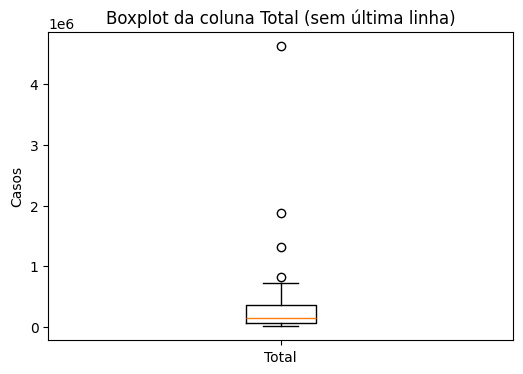

In [ ]:
# remover última linha que tem o somatório dos totais
total_sem_ultima = df["Total"].iloc[:-1]

plt.figure(figsize=(6, 4))
plt.boxplot(total_sem_ultima, tick_labels=["Total"])

plt.title("Boxplot da coluna Total (sem última linha)")
plt.ylabel("Casos")

plt.show()

### Mostrando os primeiros valores para uma inspeção visual. Verifique existência de valores NaN

In [ ]:
df.head(n=10)

,Região/Unidade da Federação,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,Total
0,Região Norte,16834.0,18855.0,19149.0,20848.0,21228.0,20465.0,19407.0,18429.0,17455.0,18118.0,18846.0,18863.0,16278.0,18166.0,20906.0,21260.0,23002.0,22882.0,352270.0
1,.. Rondônia,2364.0,3144.0,3090.0,3228.0,2905.0,3050.0,3058.0,2732.0,2455.0,2715.0,2799.0,2614.0,2327.0,2670.0,2611.0,2760.0,2898.0,2690.0,50200.0
2,.. Acre,861.0,833.0,687.0,776.0,755.0,757.0,697.0,777.0,707.0,631.0,702.0,588.0,541.0,691.0,821.0,942.0,962.0,1025.0,13806.0
3,.. Amazonas,2300.0,2500.0,2626.0,2766.0,3539.0,3241.0,2293.0,3012.0,3306.0,3474.0,3889.0,3669.0,3160.0,3933.0,5021.0,4677.0,4715.0,5349.0,63661.0
4,.. Roraima,609.0,846.0,816.0,800.0,664.0,767.0,764.0,716.0,639.0,690.0,731.0,886.0,648.0,707.0,839.0,975.0,885.0,644.0,13641.0
5,.. Pará,7968.0,8841.0,9153.0,10469.0,10587.0,10030.0,10133.0,9283.0,8545.0,8895.0,8978.0,9325.0,7963.0,8451.0,9689.0,9819.0,11409.0,11081.0,171319.0
6,.. Amapá,569.0,608.0,534.0,578.0,645.0,618.0,502.0,402.0,360.0,375.0,402.0,388.0,300.0,433.0,500.0,657.0,618.0,846.0,9387.0
7,.. Tocantins,2163.0,2083.0,2243.0,2231.0,2133.0,2002.0,1960.0,1507.0,1443.0,1338.0,1345.0,1393.0,1339.0,1281.0,1425.0,1430.0,1515.0,1247.0,30256.0
8,Região Nordeste,73698.0,80471.0,85799.0,85617.0,80109.0,80144.0,78901.0,77470.0,69765.0,69634.0,68638.0,70262.0,56566.0,61813.0,67881.0,67820.0,69849.0,71153.0,1319957.0
9,.. Maranhão,5371.0,6460.0,7163.0,8312.0,8033.0,9468.0,10272.0,10628.0,9480.0,11097.0,11699.0,12724.0,10130.0,11870.0,13882.0,13859.0,11757.0,11439.0,184099.0


### Verifique se alguma das colunas apresenta uma menor contagem de elementos. Isso indica valores NaN

In [ ]:
print(df.describe())

                2008           2009           2010           2011  \
count      33.000000      33.000000      33.000000      33.000000   
mean    24649.090909   25941.909091   27268.636364   26242.000000   
std     49992.587189   52575.527681   55360.322302   53189.360828   
min       569.000000     608.000000     534.000000     578.000000   
25%      3498.000000    3454.000000    4324.000000    4449.000000   
50%      7588.000000    7724.000000    8206.000000    8312.000000   
75%     20119.000000   21253.000000   20805.000000   20848.000000   
max    271140.000000  285361.000000  299955.000000  288662.000000   

                2012           2013           2014           2015  \
count      33.000000      33.000000      33.000000      33.000000   
mean    25531.363636   24882.363636   24406.545455   23550.090909   
std     51837.608587   50505.608602   49653.346512   47979.826912   
min       645.000000     618.000000     502.000000     402.000000   
25%      3869.000000    3825.0000

# Removendo o valores NaN



In [ ]:
df.dropna(inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 33 entries, 0 to 32
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Região/Unidade da Federação  33 non-null     object 
 1   2008                         33 non-null     float64
 2   2009                         33 non-null     float64
 3   2010                         33 non-null     float64
 4   2011                         33 non-null     float64
 5   2012                         33 non-null     float64
 6   2013                         33 non-null     float64
 7   2014                         33 non-null     float64
 8   2015                         33 non-null     float64
 9   2016                         33 non-null     float64
 10  2017                         33 non-null     float64
 11  2018                         33 non-null     float64
 12  2019                         33 non-null     float64
 13  2020                       

In [ ]:
df.head(n=10)


,Região/Unidade da Federação,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,Total
0,Região Norte,16834.0,18855.0,19149.0,20848.0,21228.0,20465.0,19407.0,18429.0,17455.0,18118.0,18846.0,18863.0,16278.0,18166.0,20906.0,21260.0,23002.0,22882.0,352270.0
1,.. Rondônia,2364.0,3144.0,3090.0,3228.0,2905.0,3050.0,3058.0,2732.0,2455.0,2715.0,2799.0,2614.0,2327.0,2670.0,2611.0,2760.0,2898.0,2690.0,50200.0
2,.. Acre,861.0,833.0,687.0,776.0,755.0,757.0,697.0,777.0,707.0,631.0,702.0,588.0,541.0,691.0,821.0,942.0,962.0,1025.0,13806.0
3,.. Amazonas,2300.0,2500.0,2626.0,2766.0,3539.0,3241.0,2293.0,3012.0,3306.0,3474.0,3889.0,3669.0,3160.0,3933.0,5021.0,4677.0,4715.0,5349.0,63661.0
4,.. Roraima,609.0,846.0,816.0,800.0,664.0,767.0,764.0,716.0,639.0,690.0,731.0,886.0,648.0,707.0,839.0,975.0,885.0,644.0,13641.0
5,.. Pará,7968.0,8841.0,9153.0,10469.0,10587.0,10030.0,10133.0,9283.0,8545.0,8895.0,8978.0,9325.0,7963.0,8451.0,9689.0,9819.0,11409.0,11081.0,171319.0
6,.. Amapá,569.0,608.0,534.0,578.0,645.0,618.0,502.0,402.0,360.0,375.0,402.0,388.0,300.0,433.0,500.0,657.0,618.0,846.0,9387.0
7,.. Tocantins,2163.0,2083.0,2243.0,2231.0,2133.0,2002.0,1960.0,1507.0,1443.0,1338.0,1345.0,1393.0,1339.0,1281.0,1425.0,1430.0,1515.0,1247.0,30256.0
8,Região Nordeste,73698.0,80471.0,85799.0,85617.0,80109.0,80144.0,78901.0,77470.0,69765.0,69634.0,68638.0,70262.0,56566.0,61813.0,67881.0,67820.0,69849.0,71153.0,1319957.0
9,.. Maranhão,5371.0,6460.0,7163.0,8312.0,8033.0,9468.0,10272.0,10628.0,9480.0,11097.0,11699.0,12724.0,10130.0,11870.0,13882.0,13859.0,11757.0,11439.0,184099.0


### Gera modelo de regressão dos valores totais

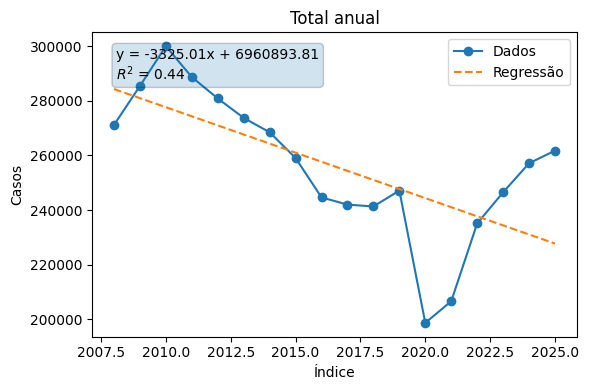

In [ ]:
x = df.columns.values[1:-1].astype(int)
y = df.iloc[-1, 1:-1].values.astype(int)

# modelo de regressão
model = LinearRegression()
X = x.reshape(-1, 1)
model.fit(X, y)
y_pred = model.predict(X)

# coeficientes
a = model.coef_[0]
b = model.intercept_
r2 = model.score(X, y)

# plot
plt.figure(figsize=(6, 4))

plt.plot(x, y, marker='o', label="Dados")
plt.plot(x, y_pred, linestyle='--', label="Regressão")

plt.title("Total anual")
plt.xlabel("Índice")
plt.ylabel("Casos")

# equação no gráfico
eq_text = f"y = {a:.2f}x + {b:.2f}\n$R^2$ = {r2:.2f}"
plt.text(0.05, 0.95, eq_text,
         transform=plt.gca().transAxes,
         verticalalignment='top',
         bbox=dict(boxstyle="round", alpha=0.2))

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# --- preparar dados ---
colunas_anos = [c for c in df.columns if c.isdigit()]
anos = np.array(colunas_anos, dtype=int)

# matriz de valores
Y = df[colunas_anos].astype(float).values

# matriz X com intercepto (uma vez só)
X = sm.add_constant(anos)

# --- regressão ---
slopes = []
interceptos = []
p_values = []
r2_adj = []
medias = []

for y in Y:
    model = sm.OLS(y, X).fit()

    slopes.append(model.params[1])
    interceptos.append(model.params[0])
    p_values.append(model.pvalues[1])
    r2_adj.append(model.rsquared_adj)
    medias.append(y.mean())

# converter para array
slopes = np.array(slopes)
medias = np.array(medias)

razoes = slopes / medias

# --- dataframe final ---
resultados_df = pd.DataFrame({
    "Regiao": df.iloc[:, 0],
    "Coef_Angular": slopes,
    "Intercepto": interceptos,
    "p_valor": p_values,
    "R2_ajustado": r2_adj,
    "Media": medias,
    "Razao": razoes
}).sort_values(by="Razao", ascending=False)

resultados_df.head(n=110)

,Regiao,Coef_Angular,Intercepto,p_valor,R2_ajustado,Media,Razao
3,.. Amazonas,153.956656,-3.069275e+05,9.570678e-07,0.772715,3526.111111,0.043662
9,.. Maranhão,399.572755,-7.955360e+05,1.195392e-06,0.766405,10202.444444,0.039164
25,.. Santa Catarina,112.014448,-2.178388e+05,1.168838e-02,0.294521,8038.333333,0.013935
16,.. Sergipe,18.283798,-3.512678e+04,2.514825e-01,0.023865,1742.500000,0.010493
2,.. Acre,5.778122,-1.088753e+04,3.350021e-01,-0.000700,764.055556,0.007562
0,Região Norte,139.761610,-2.623298e+05,1.101613e-01,0.098645,19499.500000,0.007167
20,.. Espírito Santo,36.062951,-6.740033e+04,5.715533e-02,0.158469,5320.611111,0.006778
5,.. Pará,54.923633,-1.012747e+05,2.386390e-01,0.028482,9478.833333,0.005794
4,.. Roraima,4.061920,-7.433861e+03,4.001081e-01,-0.015089,757.000000,0.005366
11,.. Ceará,20.102167,-3.291474e+04,6.877169e-01,-0.051488,7621.277778,0.002638


É importante analisar os coeficientes e as métricas dos modelos de regressão.
Tendo-se que a equação do modelo de regressão é $Y = ax + b$
* Coef_Angular ($a$): representa a inclinação da reta de regressão, indicando a variação média da variável dependente ($Y$) para cada unidade de aumento da variável independente ($X$). Valores positivos indicam tendência crescente, enquanto valores negativos indicam tendência decrescente.

* Intercepto ($b$): corresponde ao valor estimado de $Y$ quando $X = 0$. Ele define o ponto em que a reta intercepta o eixo $Y$ e, dependendo do contexto, pode ou não ter interpretação prática relevante.

As métricas do modelo de regressão são:
* $p-valor$: avalia a significância estatística do coeficiente estimado, testando a hipótese nula de que o coeficiente é igual a zero (ou seja, sem efeito). Valores de $p$ menores que um nível de significância (ex.: 0,05) indicam evidência de que a variável independente tem efeito estatisticamente significativo sobre $Y$.

* $R^2$-ajustado: mede a proporção da variabilidade de $Y$ explicada pelo modelo, ajustada pelo número de variáveis independentes. Diferentemente do $R^2$ simples, o $R^2$-ajustado penaliza a inclusão de variáveis desnecessárias, sendo mais apropriado para comparar modelos com diferentes números de preditores. Valores mais próximos de 1 indicam melhor ajuste do modelo aos dados.




### a) Mostrando o comportamento das regiões extremas: com maior crescimento e menor crescimento.

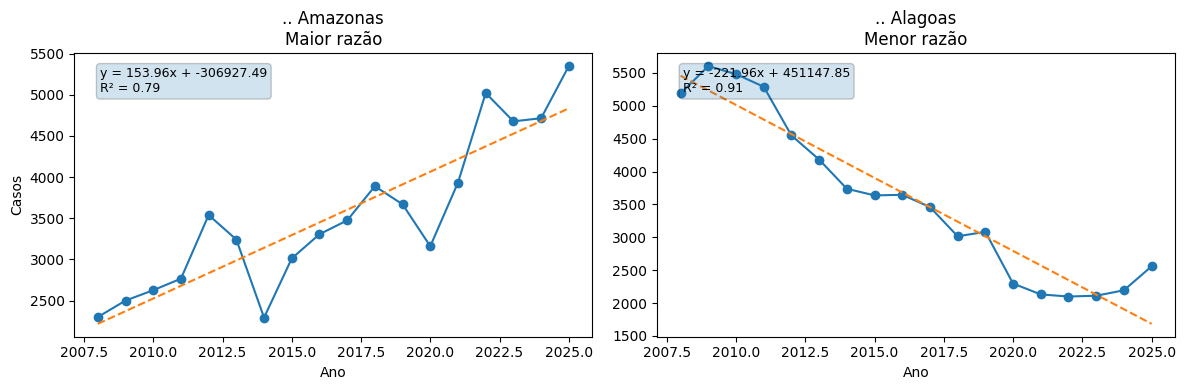

In [ ]:
# --- identificar extremos ---
regiao_max = resultados_df.iloc[0]["Regiao"]
# Filter out NaN 'Razao' values before selecting the minimum region
regiao_min = resultados_df.dropna(subset=['Razao']).iloc[-1]["Regiao"]

# --- função para obter série ---
def get_series(regiao):
    return df.loc[df.iloc[:, 0] == regiao, colunas_anos].values.flatten()

# --- função para tendência + coeficientes ---
def trend(anos, y):
    model = LinearRegression()
    X = np.array(anos).reshape(-1, 1)
    model.fit(X, y)

    y_pred = model.predict(X)
    a = model.coef_[0]
    b = model.intercept_
    r2 = model.score(X, y)

    return y_pred, a, b, r2

# --- dados ---
y_max = get_series(regiao_max)
y_min = get_series(regiao_min)

ymax_pred, a_max, b_max, r2_max = trend(anos, y_max)
ymin_pred, a_min, b_min, r2_min = trend(anos, y_min)

# --- plot ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

x_vals = anos.flatten()

# maior razão
axes[0].plot(x_vals, y_max, marker='o')
axes[0].plot(x_vals, ymax_pred, linestyle='--')
axes[0].set_title(f"{regiao_max}\nMaior razão")
axes[0].set_xlabel("Ano")
axes[0].set_ylabel("Casos")

eq_max = f"y = {a_max:.2f}x + {b_max:.2f}\nR² = {r2_max:.2f}"
axes[0].text(
    0.05, 0.95, eq_max,
    transform=axes[0].transAxes,
    fontsize=9,
    verticalalignment='top',
    bbox=dict(boxstyle="round", alpha=0.2)
)

# menor razão
axes[1].plot(x_vals, y_min, marker='o')
axes[1].plot(x_vals, ymin_pred, linestyle='--')
axes[1].set_title(f"{regiao_min}\nMenor razão")
axes[1].set_xlabel("Ano")

eq_min = f"y = {a_min:.2f}x + {b_min:.2f}\nR² = {r2_min:.2f}"
axes[1].text(
    0.05, 0.95, eq_min,
    transform=axes[1].transAxes,
    fontsize=9,
    verticalalignment='top',
    bbox=dict(boxstyle="round", alpha=0.2)
)

plt.tight_layout()
plt.show()

### Mostrando o comportamento de todas as regiões.

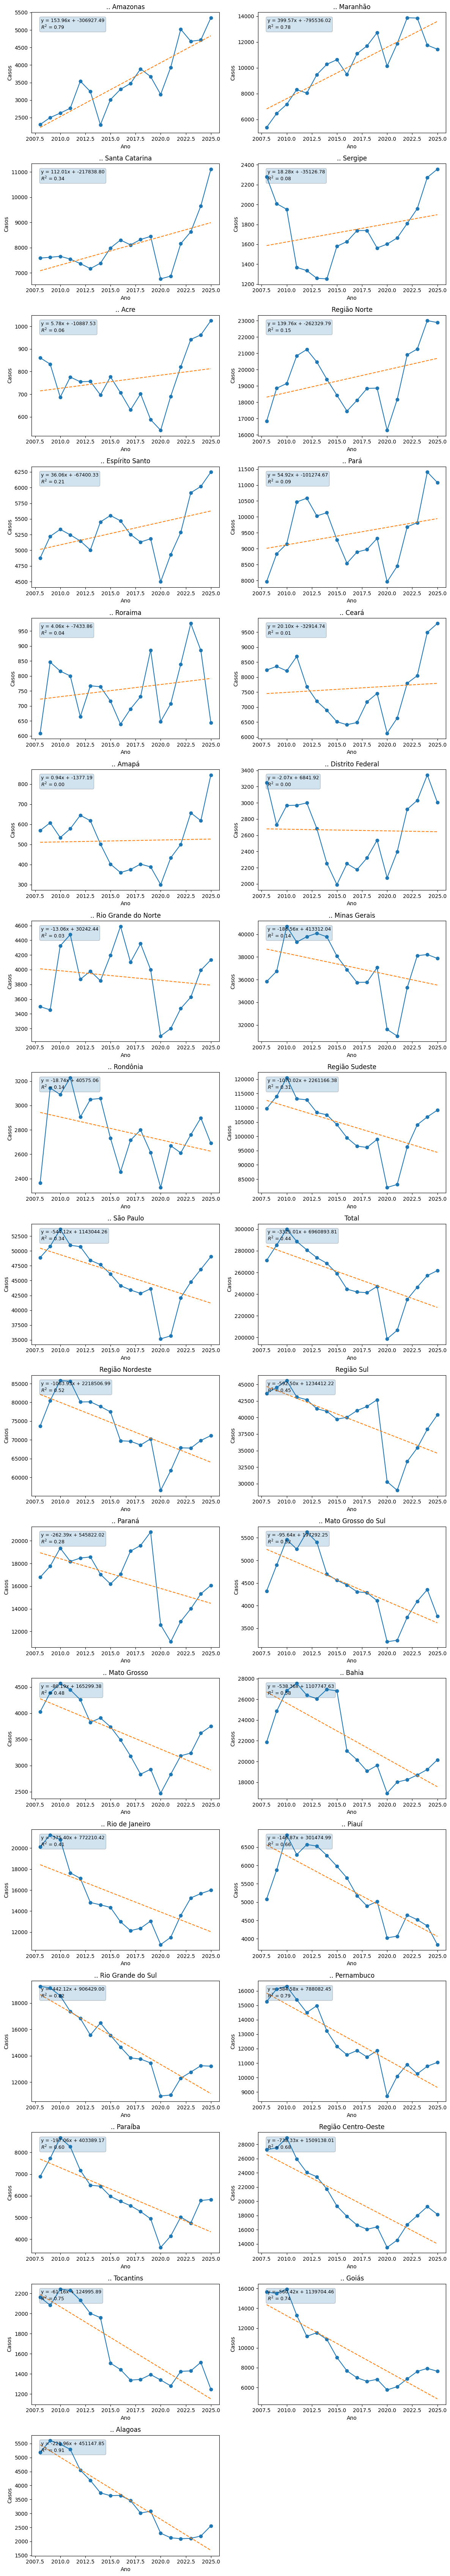

In [ ]:
# --- função para obter série ---
def get_series(regiao):
    return df.loc[df.iloc[:, 0] == regiao, colunas_anos].values.flatten()

# --- função para tendência + coeficientes ---
def trend(anos, y):
    model = LinearRegression()
    X = np.array(anos).reshape(-1, 1)
    model.fit(X, y)
    y_pred = model.predict(X)

    a = model.coef_[0]
    b = model.intercept_
    r2 = model.score(X, y)  # <-- cálculo do R²

    return y_pred, a, b, r2

# --- lista de regiões ---
regioes = resultados_df["Regiao"].tolist()

# --- layout ---
n = len(regioes)
ncols = 2
nrows = math.ceil(n / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4 * nrows))
axes = axes.reshape(nrows, ncols)

# --- loop ---
for i, regiao in enumerate(regioes):
    row = i // ncols
    col = i % ncols

    ax = axes[row, col]

    y = get_series(regiao)
    y_pred, a, b, r2 = trend(anos, y)

    x_vals = anos.flatten()

    ax.plot(x_vals, y, marker='o')
    ax.plot(x_vals, y_pred, linestyle='--')

    ax.set_title(f"{regiao}")
    ax.set_xlabel("Ano")
    ax.set_ylabel("Casos")

    # --- equação + R² ---
    eq_text = f"y = {a:.2f}x + {b:.2f}\n$R^2$ = {r2:.2f}"

    ax.text(
        0.05, 0.95, eq_text,
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment='top',
        bbox=dict(boxstyle="round", alpha=0.2)
    )

# --- remover eixos vazios ---
for j in range(i + 1, nrows * ncols):
    fig.delaxes(axes.flatten()[j])

plt.tight_layout()
plt.show()